# Загрузка и очистка данных

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, ttest_ind, shapiro, binom

In [25]:
df = pd.read_csv('data_ab.csv')

In [26]:
df.isnull().sum()

,0
user_id,0
timestamp,0
group,0
landing_page,0
converted,0


In [27]:
len(df)

294478

In [28]:
df_clean = df.dropna(subset = ['converted', 'landing_page', 'timestamp'])
len(df_clean)

294478

все строки полны

In [29]:
df_clean['group'] = df_clean['group'].str.replace('treatmentt', 'treatment')
df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'])
df_clean['converted'] = df_clean['converted'].astype(int)

In [30]:
df_clean

,user_id,timestamp,group,landing_page,converted
0,851104,2025-01-21 22:11:48.556739,control,old_page,0
1,804228,2025-01-12 08:01:45.159739,control,old_page,0
2,661590,2025-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2025-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2025-01-21 01:52:26.210827,control,old_page,1
...,...,...,...,...,...
294473,751197,2025-01-03 22:28:38.630509,control,old_page,0
294474,945152,2025-01-12 00:51:57.078372,control,old_page,0
294475,734608,2025-01-22 11:45:03.439544,control,old_page,0
294476,697314,2025-01-15 01:20:28.957438,control,old_page,0


In [31]:
valid_mapping = (
    ((df_clean['group'] == 'control') & (df_clean['landing_page'] == 'old_page')) |
    ((df_clean['group'] == 'treatment') & (df_clean['landing_page'] == 'new_page'))
)
df_clean = df_clean[valid_mapping]

In [32]:
print(df_clean.shape)

(290585, 5)


# EDA

In [33]:
for group in ['control', 'treatment']:
    group_data = df_clean[df_clean['group'] == group]
    n = len(group_data)
    conversions = group_data['converted'].sum()
    cr = conversions / n

    print(group.upper)
    print(n)
    print(conversions)
    print(cr)

<built-in method upper of str object at 0x79858e276df0>
145274
17489
0.1203863045004612
<built-in method upper of str object at 0x79857d5f2c30>
145311
17264
0.11880724790277405


In [12]:
control_data = df_clean[df_clean['group'] == 'control']
treatment_data = df_clean[df_clean['group'] == 'treatment']

n_control = len(control_data)
n_treatment = len(treatment_data)
conversions_control = control_data['converted'].sum()
conversions_treatment = treatment_data['converted'].sum()

cr_control = conversions_control / n_control
cr_treatment = conversions_treatment / n_treatment

abs_diff = cr_treatment - cr_control
rel_diff = (cr_treatment - cr_control) / cr_control * 100

print(f"Абсолютная: {abs_diff*100:+.2f} пп")
print(f"Относительная: {rel_diff:+.2f}%")

Абсолютная: -0.07 пп
Относительная: -0.62%


In [13]:
group_counts = df_clean['group'].value_counts()
print(group_counts)

chi2_balance, p_balance = stats.chisquare([n_control, n_treatment])
print(chi2_balance)
print(p_balance)

group
treatment    67148
control      66893
Name: count, dtype: int64
0.4851127640050432
0.48611552627258914


p_balance >> 0.05, группы сбалансированы

/tmp/ipython-input-3724031342.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['date'] = df_clean['timestamp'].dt.date


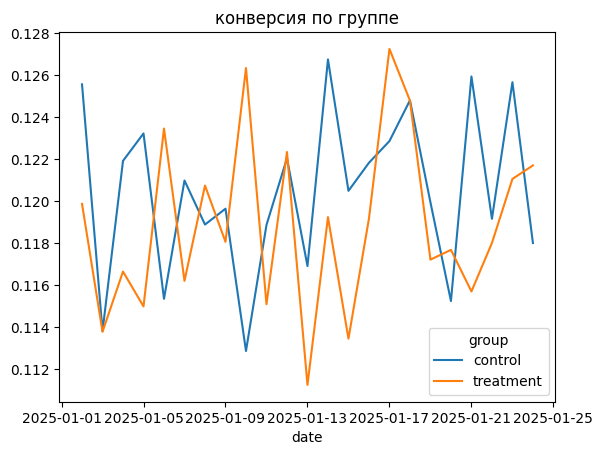

In [34]:
df_clean['date'] = df_clean['timestamp'].dt.date
daily_cr = df_clean.groupby(['date', 'group'])['converted'].mean().unstack()
daily_cr.plot(title='конверсия по группе')
plt.show()

Из-за такой волатильности визуальный анализ ненадежен. Выводы о том, какая версия лучше, можно сделать только с помощью **статистических тестов**.

Визуально сложно сказать, какая группа выигрывает. Линии часто пересекаются, и ни одна из них не находится стабильно выше другой. Иногда лидирует синяя линия, иногда оранжевая.

Возможно, есть сильная сегментация трафика, которая неравномерно распределяется между группами. Например, по вечерам приходит более качественный трафик с высоким CR, и он чаще попадает в одну группу, чем в другую.

In [15]:
print(df_clean['group'].unique())

['control' 'treatment']


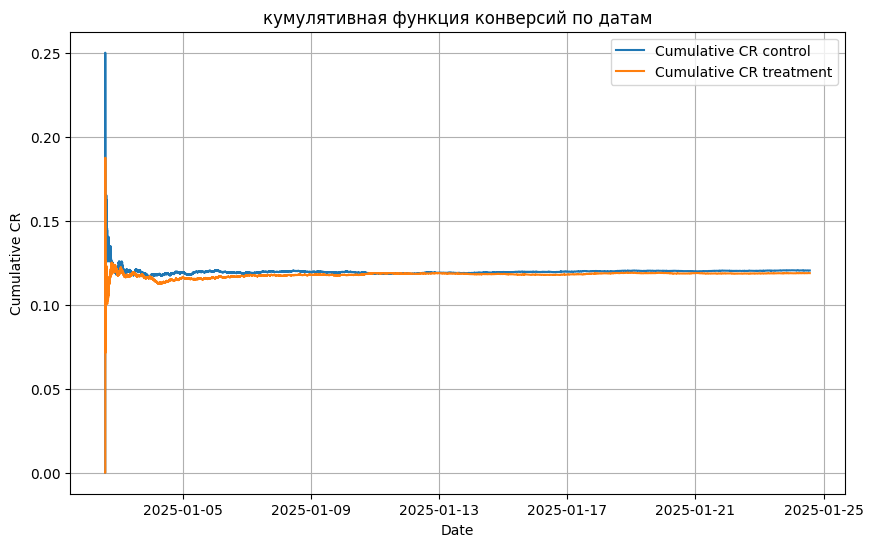

In [40]:
df_clean = df_clean.sort_values('timestamp')

# рассчитываем кумулятивные суммы конверсий и пользователей для каждой группы и используем .cumsum() для накопления значений))
df_cumulative_results = df_clean.groupby(['group', 'timestamp']).agg(
    conversions_total=('converted', 'sum'),
    users_total=('converted', 'count')
).groupby(level=0).cumsum().reset_index()

df_cumulative_results['cumulative_cr'] = df_cumulative_results['conversions_total'] / df_cumulative_results['users_total']

plt.figure(figsize=(10, 6))

for group_name, group_subset in df_cumulative_results.groupby('group'):
    plt.plot(group_subset['timestamp'], group_subset['cumulative_cr'], label=f'Cumulative CR {group_name}')

plt.title('кумулятивная функция конверсий по датам')
plt.xlabel('Date')
plt.ylabel('Cumulative CR')
plt.legend()
plt.grid(True)
plt.show()

Исходя из этого графика, можно сделать вывод, что статистически значимой разницы между контрольной и тестовой версиями, скорее всего, нет. Тестовая версия (treatment) не показала себя лучше, чем старая (control). Обе страницы имеют примерно одинаковую эффективность. Но следует также провести статистические тесты чтобы точно в этом убедиться

# Гипотезы

Нулевая гипотеза : между конверсией в контрольной и экспериментальной группах нет статистически значимого различия.

Альтернативная гипотеза : между конверсией в контрольной и экспериментальной группах есть статистически значимое различие.

# Статистические тесты

In [18]:
contingency = pd.crosstab(
    df_clean['group'],
    df_clean['converted'],
    margins=True
)
print(contingency)

converted       0      1     All
group                           
control     58857   8036   66893
treatment   59131   8017   67148
All        117988  16053  134041


In [35]:
chi2, p_chi2, dof, expected = chi2_contingency(
    pd.crosstab(df_clean['group'], df_clean['converted'])
)

print(chi2)
print(dof)
print(p_chi2)

1.7053502645115002
1
0.19158976298516003


In [38]:
p_pool = (conversions_control + conversions_treatment) / (n_control + n_treatment)
se_z = np.sqrt(p_pool * (1 - p_pool) * (1/n_control + 1/n_treatment))
z_stat = (cr_control - cr_treatment) / se_z
p_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(cr_control)
print(cr_treatment)
print(cr_control - cr_treatment)
print(p_pool)
print(se_z)
print(z_stat)
print(p_z)

0.12013215134617972
0.11939298266515756
0.0007391686810221537
0.11976186390731194
0.0017736638534804668
0.4167467694465783
0.6768636412326026


In [39]:
u_stat, p_mw = mannwhitneyu(
    control_data['converted'],
    treatment_data['converted'],
    alternative='two-sided'
)

print(u_stat)
print(p_mw)

2247525655.5
0.6768648702402849


Наблюдаемая разница в конверсии (Control CR: 12.04% против Treatment CR: 11.88%; **разница всего +0.16%**) настолько мала, что она, скорее всего, является результатом случайности

Исходя из этих данных, новая страница **неэффективна** с точки зрения повышения конверсии. Нет смысла ее внедрять на постоянной основе, так как она не приносит измеримой пользы по сравнению со старой версией.